<a href="https://colab.research.google.com/github/mahaairshad-shu/Hackathon-SERG_SHU_UoM_Nov2026/blob/main/3D_body_skeleton_Mediapipe.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


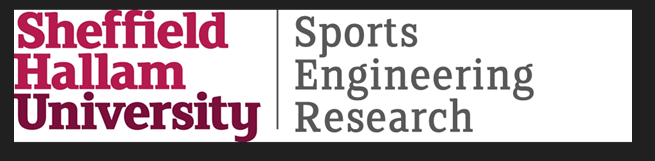

#3D body skeleton tracking

###MediaPipe 3D
[Mediapipe by Google](https://ai.google.dev/edge/mediapipe/solutions/vision/pose_landmarker)

For pose estimation we'll use an off-the-shelf pre-trained Mediapipe 3D pose model.

As the model is pre-trained, we'll only run it on our video (test data).


The MediaPipe Pose model is a machine learning solution developed by Google that estimates 33 3D landmarks of a human body from a single image or video frame. It's designed to be lightweight and run in real-time on various devices, providing accurate and robust pose estimation even in challenging conditions. The model is valuable for applications like fitness tracking, augmented reality, and gesture recognition, as it allows for the analysis and understanding of human movement.

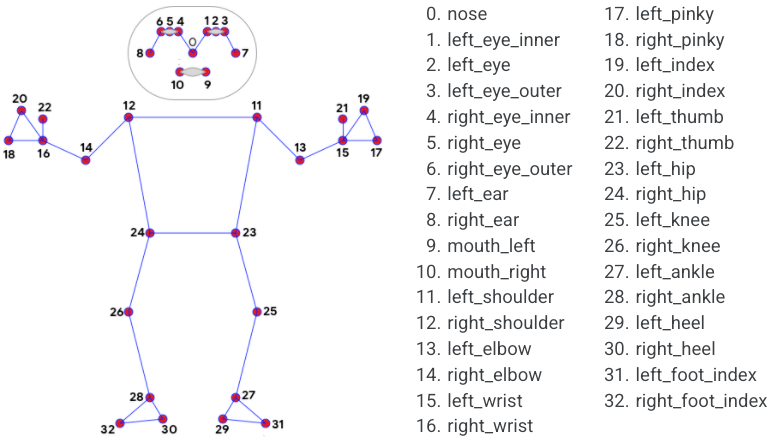

In [ ]:
'''landmark_map = {
    'nose': 0,
    'left_eye_inner': 1,
    'left_eye' : 2,
    'left_eye_outer': 3,
    'right_eye_inner': 4,
    'right_eye': 5,
    'right_eye_outer': 6,
    'left_ear': 7,
    'right_ear': 8,
    'mouth_left': 9,
    'mouth_right': 10,
    'left_shoulder': 11,
    'right_shoulder': 12,
    'left_elbow': 13,
    'right_elbow': 14,
    'left_wrist': 15,
    'right_wrist': 16,
    'left_pinky': 17,
    'right_pinky': 18,
    'left_index': 19,
    'right_index': 20,
    'left_thumb': 21,
    'right_thumb': 22,
    'left_hip': 23,
    'right_hip': 24,
    'left_knee': 25,
    'right_knee': 26,
    'left_ankle': 27,
    'right_ankle': 28,
    'left_heel': 29,
    'right_heel': 30,
    'left_foot_index': 31,
    'right_foot_index': 32
}
'''

"landmark_map = {\n    'nose': 0,\n    'left_eye_inner': 1,\n    'left_eye' : 2,\n    'left_eye_outer': 3,\n    'right_eye_inner': 4,\n    'right_eye': 5,\n    'right_eye_outer': 6,\n    'left_ear': 7,\n    'right_ear': 8,\n    'mouth_left': 9,\n    'mouth_right': 10,\n    'left_shoulder': 11,\n    'right_shoulder': 12,\n    'left_elbow': 13,\n    'right_elbow': 14,\n    'left_wrist': 15,\n    'right_wrist': 16,\n    'left_pinky': 17,\n    'right_pinky': 18,\n    'left_index': 19,\n    'right_index': 20,\n    'left_thumb': 21,\n    'right_thumb': 22,\n    'left_hip': 23,\n    'right_hip': 24,\n    'left_knee': 25,\n    'right_knee': 26,\n    'left_ankle': 27,\n    'right_ankle': 28,\n    'left_heel': 29,\n    'right_heel': 30,\n    'left_foot_index': 31,\n    'right_foot_index': 32\n}\n"

#Setup and installations

In [ ]:
!pip install mediapipe==0.10.30 opencv-python numpy
print("mediapipe 0.10.30, opencv-python, and numpy installed.")

mediapipe 0.10.30, opencv-python, and numpy installed.


change 'input_video_path' location

In [ ]:
import os
import urllib.request
import cv2
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

# 1. Download the official MediaPipe Pose Landmarker model task file if it doesn't exist
model_path = 'pose_landmarker_full.task'
if not os.path.exists(model_path):
    print("Downloading Pose Landmarker model file...")
    url = "https://storage.googleapis.com/mediapipe-models/pose_landmarker/pose_landmarker_full/float16/1/pose_landmarker_full.task"
    urllib.request.urlretrieve(url, model_path)
    print("Model downloaded successfully!")

# 2. Configure and initialize the Pose Landmarker using the modern Tasks API
base_options = python.BaseOptions(model_asset_path=model_path)
options = vision.PoseLandmarkerOptions(
    base_options=base_options,
    running_mode=vision.RunningMode.VIDEO,
    num_poses=1,
    min_pose_detection_confidence=0.5,
    min_pose_presence_confidence=0.5,
    min_tracking_confidence=0.5
)

# Instantiate the landmarker
detector = vision.PoseLandmarker.create_from_options(options)
print("Libraries imported, MediaPipe Pose Landmarker Tasks model initialized, and input video path defined.")

# Define the input video path
input_video_path = '/content/baseball1.MP4'

Libraries imported, MediaPipe Pose Landmarker Tasks model initialized, and input video path defined.


#Use Mediapipe 3D to predict skeleton on your video

In [ ]:
import numpy as np
import cv2
import mediapipe as mp

cap = cv2.VideoCapture(input_video_path)

if not cap.isOpened():
    print(f"Error: Could not open video file '{input_video_path}'")
    exit()

all_landmarks_3d = []

frame_width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
frame_height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = cap.get(cv2.CAP_PROP_FPS)

print(f"Processing video: {input_video_path}")
print(f"Resolution: {frame_width}x{frame_height}, FPS: {fps}")

# Define the output video path
output_video_path = 'output_video_with_pose.mp4'

# Define the video codec and initialize VideoWriter
fourcc = cv2.VideoWriter_fourcc(*'mp4v')
out = cv2.VideoWriter(output_video_path, fourcc, fps, (frame_width, frame_height))

# Keypoint list in order of MediaPipe Pose indices
landmark_names = [
    'nose', 'left_eye_inner', 'left_eye', 'left_eye_outer', 'right_eye_inner', 'right_eye',
    'right_eye_outer', 'left_ear', 'right_ear', 'mouth_left', 'mouth_right', 'left_shoulder',
    'right_shoulder', 'left_elbow', 'right_elbow', 'left_wrist', 'right_wrist', 'left_pinky',
    'right_pinky', 'left_index', 'right_index', 'left_thumb', 'right_thumb', 'left_hip',
    'right_hip', 'left_knee', 'right_knee', 'left_ankle', 'right_ankle', 'left_heel',
    'right_heel', 'left_foot_index', 'right_foot_index'
]

# Define standard Connections list
POSE_CONNECTIONS = [
    (11, 12), (11, 13), (13, 15), (12, 14), (14, 16), (11, 23), (12, 24), (23, 24),
    (23, 25), (24, 26), (25, 27), (26, 28), (27, 29), (28, 30), (29, 31), (30, 32),
    (27, 31), (28, 32)
]

frame_num = 0
while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        break

    # Convert the BGR frame to RGB
    image_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    # MediaPipe Tasks expects mp.Image object
    mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=image_rgb)

    # Calculate timestamp in ms
    frame_timestamp_ms = int((frame_num * 1000) / fps)

    # Detect landmarks
    detection_result = detector.detect_for_video(mp_image, frame_timestamp_ms)

    frame_landmarks_3d = []
    if detection_result.pose_landmarks:
        # Get the first detected pose landmarks
        pose_landmarks = detection_result.pose_landmarks[0]
        for idx, landmark in enumerate(pose_landmarks):
            frame_landmarks_3d.append({
                'keypoint_id': idx,
                'keypoint_name': landmark_names[idx] if idx < len(landmark_names) else f'keypoint_{idx}',
                'x': landmark.x,
                'y': landmark.y,
                'z': landmark.z,
                'visibility': landmark.visibility
            })

            # Draw landmark coordinates on the frame
            cx, cy = int(landmark.x * frame_width), int(landmark.y * frame_height)
            cv2.circle(frame, (cx, cy), 5, (245, 117, 66), -1)

        # Draw connections
        for connection in POSE_CONNECTIONS:
            start_idx, end_idx = connection
            if start_idx < len(pose_landmarks) and end_idx < len(pose_landmarks):
                start_lm = pose_landmarks[start_idx]
                end_lm = pose_landmarks[end_idx]
                pt1 = (int(start_lm.x * frame_width), int(start_lm.y * frame_height))
                pt2 = (int(end_lm.x * frame_width), int(end_lm.y * frame_height))
                cv2.line(frame, pt1, pt2, (245, 66, 230), 2)
    else:
        # Fill with NaN if no pose is detected
        for idx in range(33):
            frame_landmarks_3d.append({
                'keypoint_id': idx,
                'keypoint_name': landmark_names[idx] if idx < len(landmark_names) else f'keypoint_{idx}',
                'x': np.nan,
                'y': np.nan,
                'z': np.nan,
                'visibility': np.nan
            })

    all_landmarks_3d.append({'frame': frame_num, 'landmarks_3d': frame_landmarks_3d})

    # Write frame
    out.write(frame)
    frame_num += 1

print(f"Processed {frame_num} frames.")
cap.release()
out.release()
print("Video processing complete. 3D landmark data collected.")

Processing video: /content/baseball1.MP4
Resolution: 1920x1080, FPS: 119.88011988011988
Processed 432 frames.
Video processing complete. 3D landmark data collected.


#Save keypoints as csv

In [ ]:
import pandas as pd

processed_landmarks = []

for frame_data in all_landmarks_3d:
    frame_num = frame_data['frame']
    landmarks_3d_list = frame_data['landmarks_3d']

    if landmarks_3d_list:
        for landmark in landmarks_3d_list:
            processed_landmarks.append({
                'frame': frame_num,
                'keypoint_id': landmark['keypoint_id'],
                'keypoint_name': landmark['keypoint_name'],
                'x': landmark['x'],
                'y': landmark['y'],
                'z': landmark['z'],
                'visibility': landmark['visibility']
            })

# Create a pandas DataFrame
df_landmarks_3d = pd.DataFrame(processed_landmarks)

# Save the DataFrame to a CSV file
output_csv_path = '3d_pose_landmarks.csv'
df_landmarks_3d.to_csv(output_csv_path, index=False)

print(f"3D pose landmarks saved to '{output_csv_path}'.")
print("First 5 rows of the CSV file:")
print(df_landmarks_3d.head())


3D pose landmarks saved to '3d_pose_landmarks.csv'.
First 5 rows of the CSV file:
   frame  keypoint_id    keypoint_name         x         y         z  \
0      0            0             nose  0.661423  0.230367 -0.120610   
1      0            1   left_eye_inner  0.666171  0.216465 -0.119280   
2      0            2         left_eye  0.669443  0.215728 -0.119311   
3      0            3   left_eye_outer  0.672636  0.214821 -0.119285   
4      0            4  right_eye_inner  0.658939  0.216859 -0.104059   

   visibility  
0    0.999414  
1    0.998913  
2    0.998822  
3    0.998765  
4    0.998999  


## Display Interactive 3D Pose Plot with Slider (Plotly)

In [ ]:
import plotly.graph_objects as go

# Get unique frame numbers
unique_frames = df_landmarks_3d['frame'].unique()

plotly_frames = []
slider_steps = []

# Set fixed range for all axes (0-1) as requested by the user
plot_axis_range = [0, 1]

# Standard POSE_CONNECTIONS list mapping landmarks indices to connect
POSE_CONNECTIONS = [
    (11, 12), (11, 13), (13, 15), (12, 14), (14, 16), (11, 23), (12, 24), (23, 24),
    (23, 25), (24, 26), (25, 27), (26, 28), (27, 29), (28, 30), (29, 31), (30, 32),
    (27, 31), (28, 32)
]

# Iterate through each unique frame number
for i, frame_num in enumerate(unique_frames):
    frame_landmarks_df = df_landmarks_3d[df_landmarks_3d['frame'] == frame_num]

    if not frame_landmarks_df.empty:
        data = []

        # Scatter trace for landmarks
        scatter_trace = go.Scatter3d(
            x=frame_landmarks_df['x'],
            y=frame_landmarks_df['y'],
            z=frame_landmarks_df['z'],
            mode='markers',
            marker=dict(size=3, color='blue'),
            name=f'Landmarks Frame {frame_num}'
        )
        data.append(scatter_trace)

        # Iterate through connections and create line traces using local POSE_CONNECTIONS list
        for connection in POSE_CONNECTIONS:
            start_node_idx, end_node_idx = connection

            # Ensure the indices are within the bounds of the 33 MediaPipe landmarks
            if start_node_idx < len(frame_landmarks_df) and end_node_idx < len(frame_landmarks_df):
                start_landmark = frame_landmarks_df.iloc[start_node_idx]
                end_landmark = frame_landmarks_df.iloc[end_node_idx]

                connection_trace = go.Scatter3d(
                    x=[start_landmark['x'], end_landmark['x']],
                    y=[start_landmark['y'], end_landmark['y']],
                    z=[start_landmark['z'], end_landmark['z']],
                    mode='lines',
                    line=dict(width=2, color='red'),
                    showlegend=False # Only show legend for landmarks to avoid clutter
                )
                data.append(connection_trace)

        # Append frame data to plotly_frames
        plotly_frames.append(go.Frame(data=data, name=str(frame_num)))

        # Append slider step
        slider_steps.append({
            'method': 'animate',
            'label': str(frame_num),
            'args': [[str(frame_num)], {
                'mode': 'immediate',
                'frame': {'duration': 100, 'redraw': True},
                'transition': {'duration': 50, 'easing': 'linear'}
            }]
        })

# Create the initial data for the first frame
initial_frame_num = unique_frames[0]
initial_frame_df = df_landmarks_3d[df_landmarks_3d['frame'] == initial_frame_num]

initial_data = []
if not initial_frame_df.empty:
    initial_data.append(go.Scatter3d(
        x=initial_frame_df['x'],
        y=initial_frame_df['y'],
        z=initial_frame_df['z'],
        mode='markers',
        marker=dict(size=3, color='blue'),
        name=f'Landmarks Frame {initial_frame_num}'
    ))

    for connection in POSE_CONNECTIONS:
        start_node_idx, end_node_idx = connection
        if start_node_idx < len(initial_frame_df) and end_node_idx < len(initial_frame_df):
            start_landmark = initial_frame_df.iloc[start_node_idx]
            end_landmark = initial_frame_df.iloc[end_node_idx]
            initial_data.append(go.Scatter3d(
                x=[start_landmark['x'], end_landmark['x']],
                y=[start_landmark['y'], end_landmark['y']],
                z=[start_landmark['z'], end_landmark['z']],
                mode='lines',
                line=dict(width=2, color='red'),
                showlegend=False
            ))

# Define sliders layout
sliders = [{
    'active': 0,
    'yanchor': 'top',
    'xanchor': 'left',
    'currentvalue': {
        'font': {'size': 16},
        'prefix': 'Frame: ',
        'visible': True,
        'xanchor': 'right'
    },
    'transition': {'duration': 300, 'easing': 'cubic-in-out'},
    'pad': {'b': 10, 't': 50},
    'len': 0.9,
    'x': 0.1,
    'y': 0,
    'steps': slider_steps
}]

# Define updatemenus for play/pause button
updatemenus = [{
    'buttons': [
        {
            'args': [None, {'frame': {'duration': 100, 'redraw': True}, 'fromcurrent': True, 'transition': {'duration': 50, 'easing': 'linear'}}],
            'label': 'Play',
            'method': 'animate'
        },
        {
            'args': [[None], {'mode': 'immediate', 'transition': {'duration': 0}}],
            'label': 'Pause',
            'method': 'animate'
        }
    ],
    'direction': 'left',
    'pad': {'r': 10, 't': 87},
    'showactive': False,
    'type': 'buttons',
    'x': 0.1,
    'xanchor': 'right',
    'y': 0,
    'yanchor': 'top'
}]

# Construct the Figure
fig = go.Figure(
    data=initial_data,
    layout=go.Layout(
        scene=dict(
            xaxis=dict(title='X', range=plot_axis_range),
            yaxis=dict(title='Y', range=plot_axis_range),
            zaxis=dict(title='Z', range=[-1, 1]),
            aspectmode='cube' # Set aspectmode to 'cube' for equal scaling
        ),
        title='Interactive 3D Pose Estimation with Slider',
        hovermode='closest',
        updatemenus=updatemenus,
        sliders=sliders,
        width=900, height=700
    ),
    frames=plotly_frames
)

# Display the interactive Plotly figure
fig.show()

print("Interactive 3D pose plot with slider displayed.")

Interactive 3D pose plot with slider displayed.
